# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [2]:
# Add code here 🔧
df = pd.read_csv('cleaned_airbnb_data_7.csv')

print("Shape:", df.shape)
df.head()

Shape: (500, 95)


,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,reviews_per_month,review_score_missing,reviews_per_month_scaled,minimum_nights_scaled,review_group,reviews_per_min_night,long_term_stay,room_Entire home/apt,room_Private room,room_Shared room
0,2992450,https://www.airbnb.com/rooms/2992450,20260914164327,2026-09-16,NaN,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,https://a0.muscache.com/pictures/44627226/0e72...,4621559,https://www.airbnb.com/users/show/4621559,...,0.06,False,0.001905,1.083907,Low,0.002143,0,1,0,0
1,3820211,https://www.airbnb.com/rooms/3820211,20260914164327,2026-09-16,NaN,Restored Precinct in Center Sq. w/Parking,Step into the charming and comfy 1BR/1BA apart...,https://a0.muscache.com/pictures/hosting/Hosti...,19648678,https://www.airbnb.com/users/show/19648678,...,2.17,False,0.202857,-0.296123,Low,2.170000,0,1,0,0
2,6623339,https://www.airbnb.com/rooms/6623339,20260914164327,2026-09-16,NaN,Center Sq. Loft in Converted Precinct w/ Parking,Step into the charming and comfy 1BR/1BA apart...,https://a0.muscache.com/pictures/hosting/Hosti...,19648678,https://www.airbnb.com/users/show/19648678,...,2.50,False,0.234286,-0.296123,Low,2.500000,0,1,0,0
3,9501054,https://www.airbnb.com/rooms/9501054,20260914164327,2026-09-16,NaN,Spacious suite with full bath by Capital Center,Great location within walking distance to the ...,https://a0.muscache.com/pictures/45153167-d704...,29288920,https://www.airbnb.com/users/show/29288920,...,3.70,False,0.348571,-0.296123,Medium,3.700000,0,0,1,0
4,10768745,https://www.airbnb.com/rooms/10768745,20260914164327,2026-09-16,NaN,Alb hospital area studio bath wifi. (Red),Spacious warm studio in 1840 house close to ho...,https://a0.muscache.com/pictures/hosting/Hosti...,5691268,https://www.airbnb.com/users/show/5691268,...,7.28,False,0.689524,-0.296123,High,7.280000,0,0,1,0


### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1. Room types, locations, host information, customer reviews

2. 500 rows and 95 columns

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [3]:
# Add code here 🔧
drop_cols = [
    'post_id', 'title', 'descr', 'details', 'address',
    'id', 'listing_url', 'scrape_id', 'last_scraped',
    'name', 'description', 'picture_url',
    'host_id', 'host_url'
]

df = df.drop(columns=drop_cols, errors='ignore')

print("Shape after dropping columns:", df.shape)
df.head()

Shape after dropping columns: (500, 86)


,source,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,...,reviews_per_month,review_score_missing,reviews_per_month_scaled,minimum_nights_scaled,review_group,reviews_per_min_night,long_term_stay,room_Entire home/apt,room_Private room,room_Shared room
0,NaN,1462661762635155041,https://www.airbnb.com/users/profile/146266176...,Kenneth,NaN,13,8,13,7,"New York, NY",...,0.06,False,0.001905,1.083907,Low,0.002143,0,1,0,0
1,NaN,1463087024016718788,https://www.airbnb.com/users/profile/146308702...,Ming,NaN,12,1,12,1,"Albany, NY",...,2.17,False,0.202857,-0.296123,Low,2.170000,0,1,0,0
2,NaN,1463087024016718788,https://www.airbnb.com/users/profile/146308702...,Ming,NaN,12,1,12,1,"Albany, NY",...,2.50,False,0.234286,-0.296123,Low,2.500000,0,1,0,0
3,NaN,1465431505328745177,https://www.airbnb.com/users/profile/146543150...,Gregg,NaN,11,6,11,6,"Albany, NY",...,3.70,False,0.348571,-0.296123,Medium,3.700000,0,0,1,0
4,NaN,1462687000374947891,https://www.airbnb.com/users/profile/146268700...,Elizabeth,NaN,13,5,10,7,"Albany, NY",...,7.28,False,0.689524,-0.296123,High,7.280000,0,0,1,0


### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. I dropped columns such as post id, title, name and others because these numbers are not significant for predicting Airbnb price

2. It would make the model more complicated because the model might learn irrelvant patterns and lead to overfitting and less accurate predictions

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

Correlation with Price:
price_quote_price_per_night     1.000000
price_quote_total_price         0.932722
estimated_revenue_l365d         0.188784
host_listings_count             0.165800
availability_30                 0.127607
                                  ...   
neighbourhood_group_cleansed         NaN
bathrooms                            NaN
calendar_updated                     NaN
license                              NaN
instant_bookable                     NaN
Name: price, Length: 63, dtype: float64


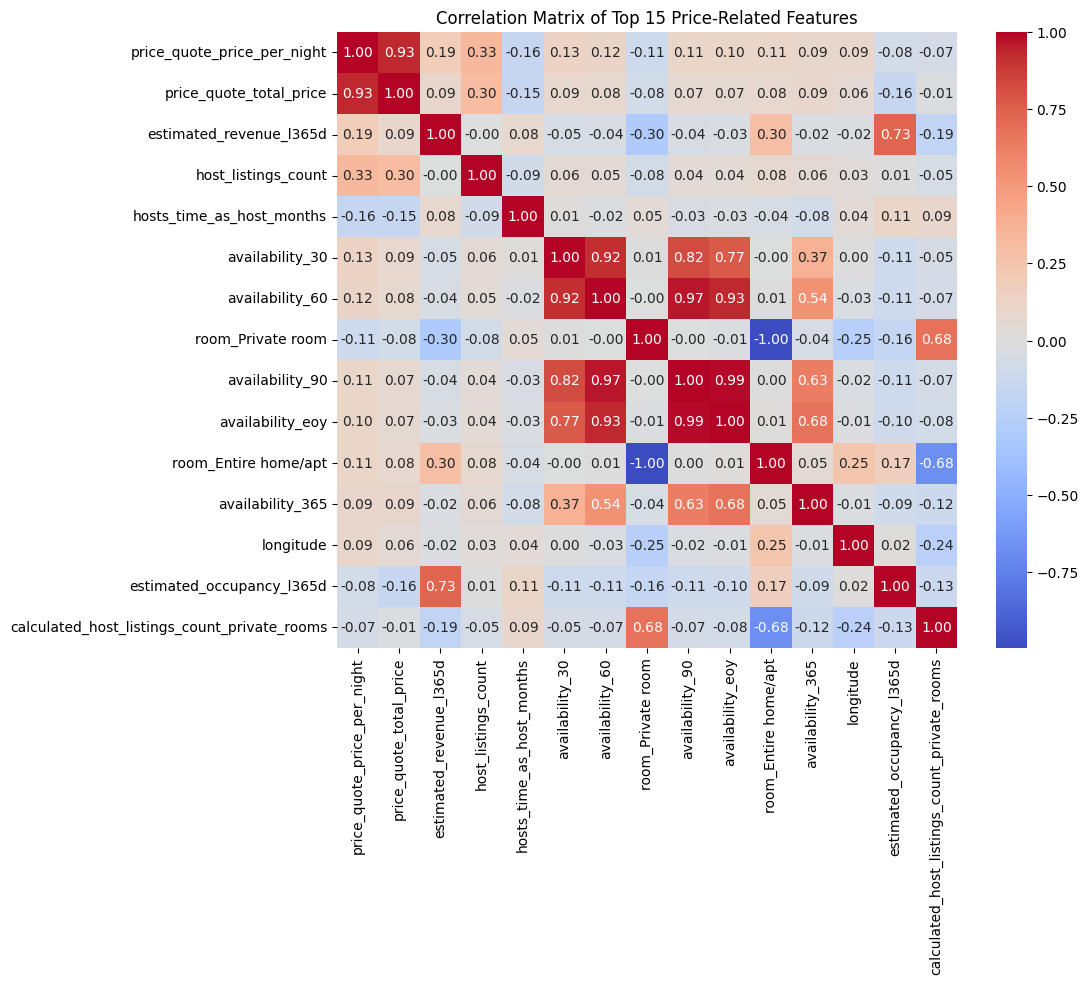

In [4]:
# Add code here 🔧
numeric_df = df.select_dtypes(include=['number'])

corr_matrix = numeric_df.corr()

price_corr = corr_matrix['price'].drop('price').sort_values(ascending=False)

print("Correlation with Price:")
print(price_corr)

top_15 = price_corr.abs().sort_values(ascending=False).head(15).index

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix.loc[top_15, top_15],
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title("Correlation Matrix of Top 15 Price-Related Features")
plt.show()

### Reflection:
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1. The strongest positve correlation is quotepricepernight which is 1.00 and the negative correlation is hosttimeashostmonths which is -0.16

2. Hostlistingcount, availability30 and room type could be useful for predictors.

## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [5]:
# Add code here 🔧
y = df['price']

X = df.drop(columns=[
    'price',
    'price_quote_price_per_night',
    'price_quote_total_price'
])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (500, 83)
Target shape: (500,)


### Reflection:
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response: 🔧
1. I am using 83 features such as host information, room type, availability, location.

2. We are prediciting the price so it is a regression.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [6]:
# Add code here 🔧
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (400, 83)
Testing Features: (100, 83)
Training Target: (400,)
Testing Target: (100,)


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [8]:
# Add code here 🔧

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

X_train = X_train.drop(columns=['estimated_revenue_l365d'], errors='ignore')
X_test = X_test.drop(columns=['estimated_revenue_l365d'], errors='ignore')

numeric_cols = X_train.select_dtypes(include=['number', 'bool']).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=['number', 'bool']).columns.tolist()

preprocessor = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), numeric_cols),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_cols)
])

linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

print("Model trained successfully!")
print("First 10 predicted prices:")
print(y_pred[:10])


Model trained successfully!
First 10 predicted prices:
[287.67810323 291.35296793 291.79369737 290.16427797 291.28433116
 255.48907157 288.64252481 291.91321146 291.87074421 290.21789856]


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_since' 'host_response_rate' 'host_acceptance_rate'
 'host_neighbourhood' 'host_total_listings_count' 'host_verifications'
 'neighbourhood' 'neighbourhood_group_cleansed' 'bathrooms'
 'calendar_updated' 'license' 'instant_bookable']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_since' 'host_response_rate' 'host_acceptance_rate'
 'host_neighbourhood' 'host_total_listings_count' 'host_verifications'
 'neighbourhood' 'neighbourhood_group_cleansed' 'bathrooms'
 'calendar_updated' 'license' 'instant_bookable']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

In [9]:
# Add code here 🔧
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2): {r2:.2f}")

Mean Squared Error (MSE): 1324120.27
R-squared (R2): 0.00


### Reflection:
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response: 🔧
1. My Rsquare value is 0 which means that the model explains none of the variation in the prices.

2. My MSE is very large which indicated significant prediction errors. To improve, maybe I could have remove extreme price outliers, select more relevant features and improve data preprocessing.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

In [10]:
# Add code here 🔧

feature_names = linear_model.named_steps['preprocessor'].get_feature_names_out()

coefficients = linear_model.named_steps['model'].coef_

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

coef_df['Absolute Coefficient'] = coef_df['Coefficient'].abs()

coef_df = coef_df.sort_values(
    by='Absolute Coefficient',
    ascending=False
)

print("Top 20 Most Impactful Features:")
print(coef_df.head(20).to_string(index=False))


Top 20 Most Impactful Features:
                           Feature   Coefficient  Absolute Coefficient
          numeric__host_profile_id -5.970770e-16          5.970770e-16
      numeric__host_listings_count  1.236003e-29          1.236003e-29
           numeric__maximum_nights -6.516546e-30          6.516546e-30
   numeric__maximum_maximum_nights -6.516546e-30          6.516546e-30
   numeric__maximum_nights_avg_ntm -6.397210e-30          6.397210e-30
   numeric__minimum_maximum_nights -6.280971e-30          6.280971e-30
         numeric__availability_365  5.893980e-30          5.893980e-30
numeric__estimated_occupancy_l365d -3.196889e-30          3.196889e-30
        numeric__number_of_reviews -2.918493e-30          2.918493e-30
         numeric__availability_eoy  1.873745e-30          1.873745e-30
          numeric__availability_90  1.606585e-30          1.606585e-30
          numeric__availability_60  1.192870e-30          1.192870e-30
          numeric__availability_30  6.924873e

### Reflection:
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response: 🔧
1. Host listing and availability 365 had the positive coefficients.

2. Maximum nights and number of reviews had negative coefficients.

3. The resulsts prove that the model is not reliable enough to predict the prices.


## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

In [11]:
# Add code here 🔧

top_5 = (
    coef_df[~coef_df['Feature'].str.contains('host_profile_id')]
    .head(5)['Feature']
    .tolist()
)

print("Top 5 Features:")
print(top_5)

X_train_encoded = linear_model.named_steps['preprocessor'].transform(X_train)
X_test_encoded = linear_model.named_steps['preprocessor'].transform(X_test)

feature_names = linear_model.named_steps['preprocessor'].get_feature_names_out()

top_indices = [list(feature_names).index(f) for f in top_5]

X_train_top5 = X_train_encoded[:, top_indices]
X_test_top5 = X_test_encoded[:, top_indices]

refined_model = LinearRegression()
refined_model.fit(X_train_top5, y_train)

y_pred_refined = refined_model.predict(X_test_top5)

mse_refined = mean_squared_error(y_test, y_pred_refined)
r2_refined = r2_score(y_test, y_pred_refined)

print("\nModel Comparison:")
print(f"Baseline MSE: {mse:.2f}")
print(f"Refined MSE: {mse_refined:.2f}")
print(f"Baseline R-squared: {r2:.4f}")
print(f"Refined R-squared: {r2_refined:.4f}")


Top 5 Features:
['numeric__host_listings_count', 'numeric__maximum_nights', 'numeric__maximum_maximum_nights', 'numeric__maximum_nights_avg_ntm', 'numeric__minimum_maximum_nights']

Model Comparison:
Baseline MSE: 1324120.27
Refined MSE: 1321208.96
Baseline R-squared: 0.0007
Refined R-squared: 0.0029


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_since' 'host_response_rate' 'host_acceptance_rate'
 'host_neighbourhood' 'host_total_listings_count' 'host_verifications'
 'neighbourhood' 'neighbourhood_group_cleansed' 'bathrooms'
 'calendar_updated' 'license' 'instant_bookable']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_since' 'host_response_rate' 'host_acceptance_rate'
 'host_neighbourhood' 'host_total_listings_count' 'host_verifications'
 'neighbourhood' 'neighbourhood_group_cleansed' 'bathrooms'
 'calendar_updated' 'license' 'instant_bookable']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


### Reflection:
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?
4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response: 🔧
1. I kept hostlistingscount, maximum nights, and others because they had the strongest absolute coefficients.

2. The model improved slightly. The MSE had decreased a little and the Rsquare value increased slightly. But the overall improvement was very small because the selected features did not explain much of variation in prices.

3. I would recommend the refined model for further analysis as it has lesser features and performs better slightly.

4. I learned how feature selection and data qualtiy is very significant for prediction accuracy. This is useful for finance because understanding model limitations is important when making investment decisions based on data.


## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. My model helped to find which factors are related to Airbnb listing prices and whether these factors can be used to predict prices.

2. I would recommend factors such as room type, location and availability when setting up their prices.

3. I would improve by removing extreme price outliers and handling missing values more carefully. I would also use other model such as random forest.

4. I learned that using more features does not always be useful for better predictions.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"